# Roll timing and implementation fidelity

**When should the portfolio roll from the expiring contract to the next one?** We compare four pre-specified timing rules for the *same* baseline outgoing/incoming pairs and select one by daily-return Tracking RMSE (basis points) against the shared 60-session constant-maturity benchmark. All results use the **real, frozen Section 0 handoff** (Databento GLBX.MDP3 CME data), not synthetic fixtures.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "config/project.yaml").is_file() and (p / "data/section0/freeze.json").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Markdown, Image
from src.validation.schemas import load_project_config, decimal_value
from src.rolling.handoff import load_timing_experiment, verify_baseline_reproduction
from src.rolling.analysis import compare_timing_rules
from src.rolling.exports import (LABELS, summary_rows, event_rows, rmse_figure, trigger_figure,
                                 write_outputs, chart_exports_verified)
config = load_project_config(ROOT / "config/project.yaml")
HANDOFF = ROOT / "data/section0"
experiment = load_timing_experiment(HANDOFF, config)  # verifies hashes, freeze, mask; never rebuilds
assert len(experiment.dates) == 148 and experiment.fixed_aum == 10_000_000
assert experiment.calendar.decision(experiment.dates[0]).decision_date == "2026-02-27"
assert all(experiment.validity[d] for d in experiment.dates)
display(pd.DataFrame([{"first_return": experiment.dates[0], "last_return": experiment.dates[-1],
    "common_dates": len(experiment.dates), "timing_reference_AUM_USD": int(experiment.fixed_aum),
    "baseline_roll_pairs": len(experiment.baseline_path.roll_events), "data": experiment.label}]))

,first_return,last_return,common_dates,timing_reference_AUM_USD,baseline_roll_pairs,data
0,2026-03-02,2026-09-30,148,10000000,10,real_frozen_databento_section0


## Methods and what is held fixed

- **Fixed -5** (baseline) and **Fixed -10**: roll 5 or 10 observed trading sessions before the outgoing contract's first-notice anchor.
- **Volume crossover** / **OI crossover**: roll on the first decision session where the incoming contract's lagged, publication-safe cleared volume (or open interest) *strictly* exceeds the outgoing contract's. The search runs from the first session the outgoing contract is held to strictly before -5; with no crossover, fall back to -5 (flagged). Agreed on Issue #23.
- **Fixed:** the 10 baseline pairs (next-deferred destination), the shared Section 0 sizing (target notional → 2.5% ADV20 capacity → nearest rounding), weights, benchmark, P&L accounting, the $10m reference AUM and the 148-date common mask.
- **Tie rule:** differences strictly below 0.1 daily bp are ties; order fixed before the real run: -5, -10, volume, OI.

In [2]:
result = compare_timing_rules(experiment, config["tracking_min_common_dates"],
                              decimal_value(config["tracking_min_candidate_survival"]))
assert verify_baseline_reproduction(result, HANDOFF)  # Fixed -5 == frozen Section 0 baseline, exactly
assert result["gates"]["passed"]
result["gates"]

{'min_common_dates': 100,
 'min_survival': Decimal('0.70'),
 'common_valid_dates': 148,
 'survival': Decimal('1'),
 'passed': True}

In [3]:
summary = pd.DataFrame(summary_rows(result))
summary["rule"] = summary["rule"].map(LABELS)
summary[["rule", "tracking_rmse_bps_daily", "delta_from_minimum_bps", "common_valid_dates",
         "survival", "fallback_events", "mean_sessions_before_anchor", "within_tie_tolerance",
         "selected"]].astype({"tracking_rmse_bps_daily": float, "delta_from_minimum_bps": float,
                               "mean_sessions_before_anchor": float}).round(6)

,rule,tracking_rmse_bps_daily,delta_from_minimum_bps,common_valid_dates,survival,fallback_events,mean_sessions_before_anchor,within_tie_tolerance,selected
0,Fixed -5 (baseline),7.258071,0.988638,148,1,0,5.0,False,False
1,Fixed -10,6.383168,0.113735,148,1,0,10.0,False,False
2,Volume crossover,6.630368,0.360935,148,1,4,13.0,False,False
3,OI crossover,6.269433,0.000000,148,1,2,16.5,True,True


## Tracking RMSE by timing rule

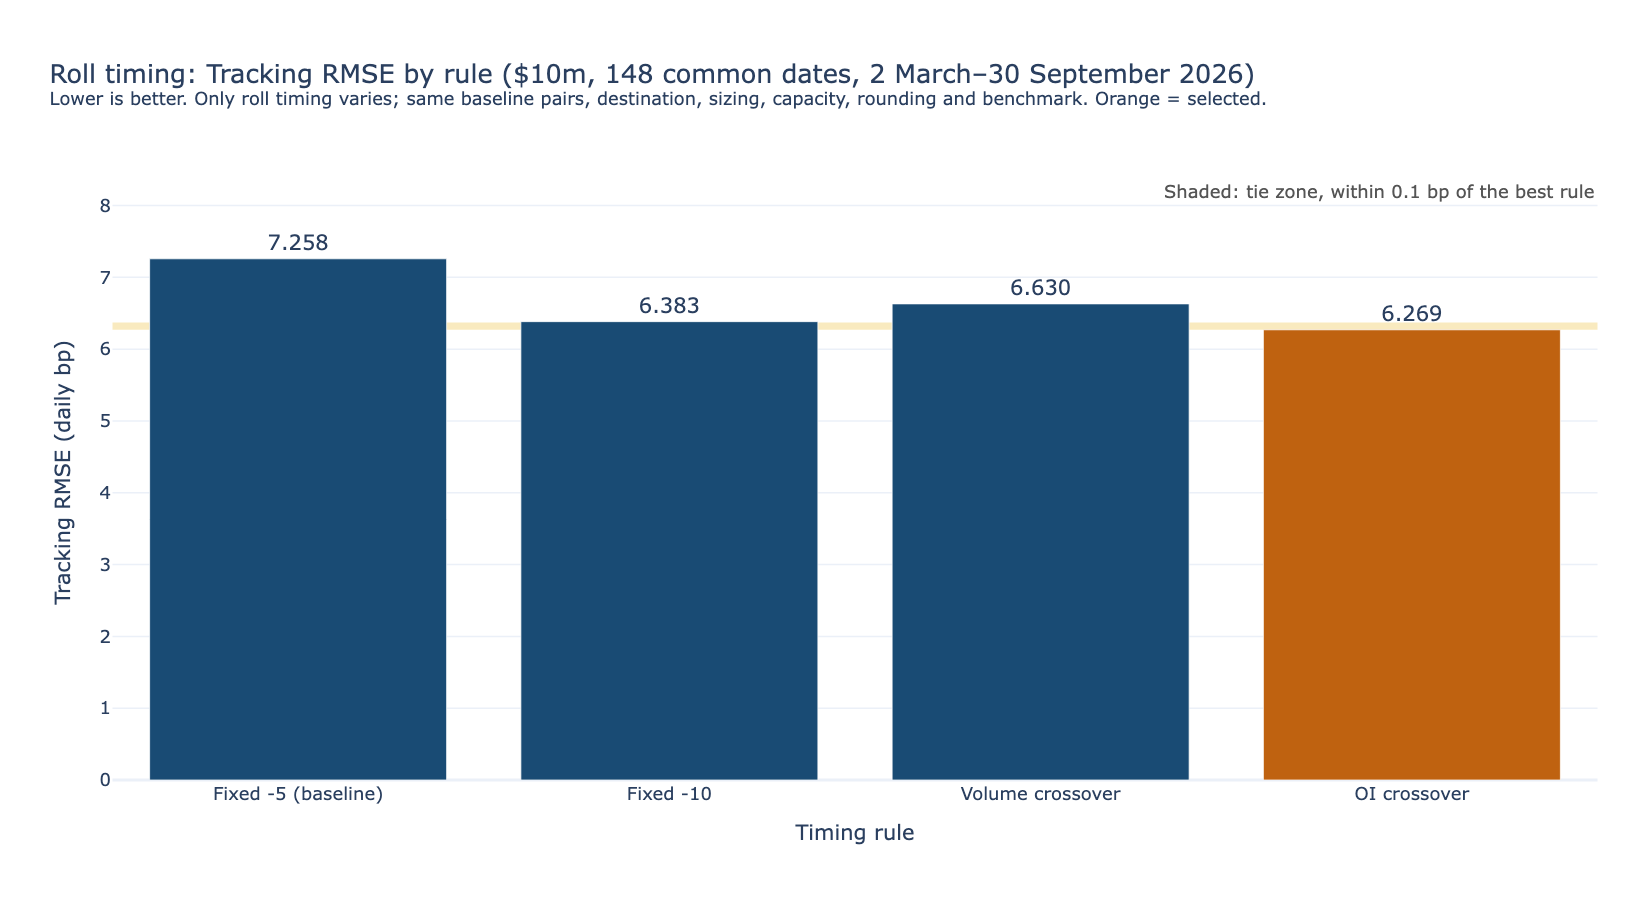

In [4]:
out = ROOT / "outputs/person2"
png = out / "tracking_rmse_by_roll_rule.png"
display(Image(png)) if png.exists() else rmse_figure(result).show()

## Why: when each rule rolled

Diagnostic only, not a ranking metric. Diamonds mark crossovers that fired on the first permitted session: the incoming contract already out-traded the thin September contract (ZC Sep→Dec, ZS Sep→Nov), so both crossover rules largely bypass September.

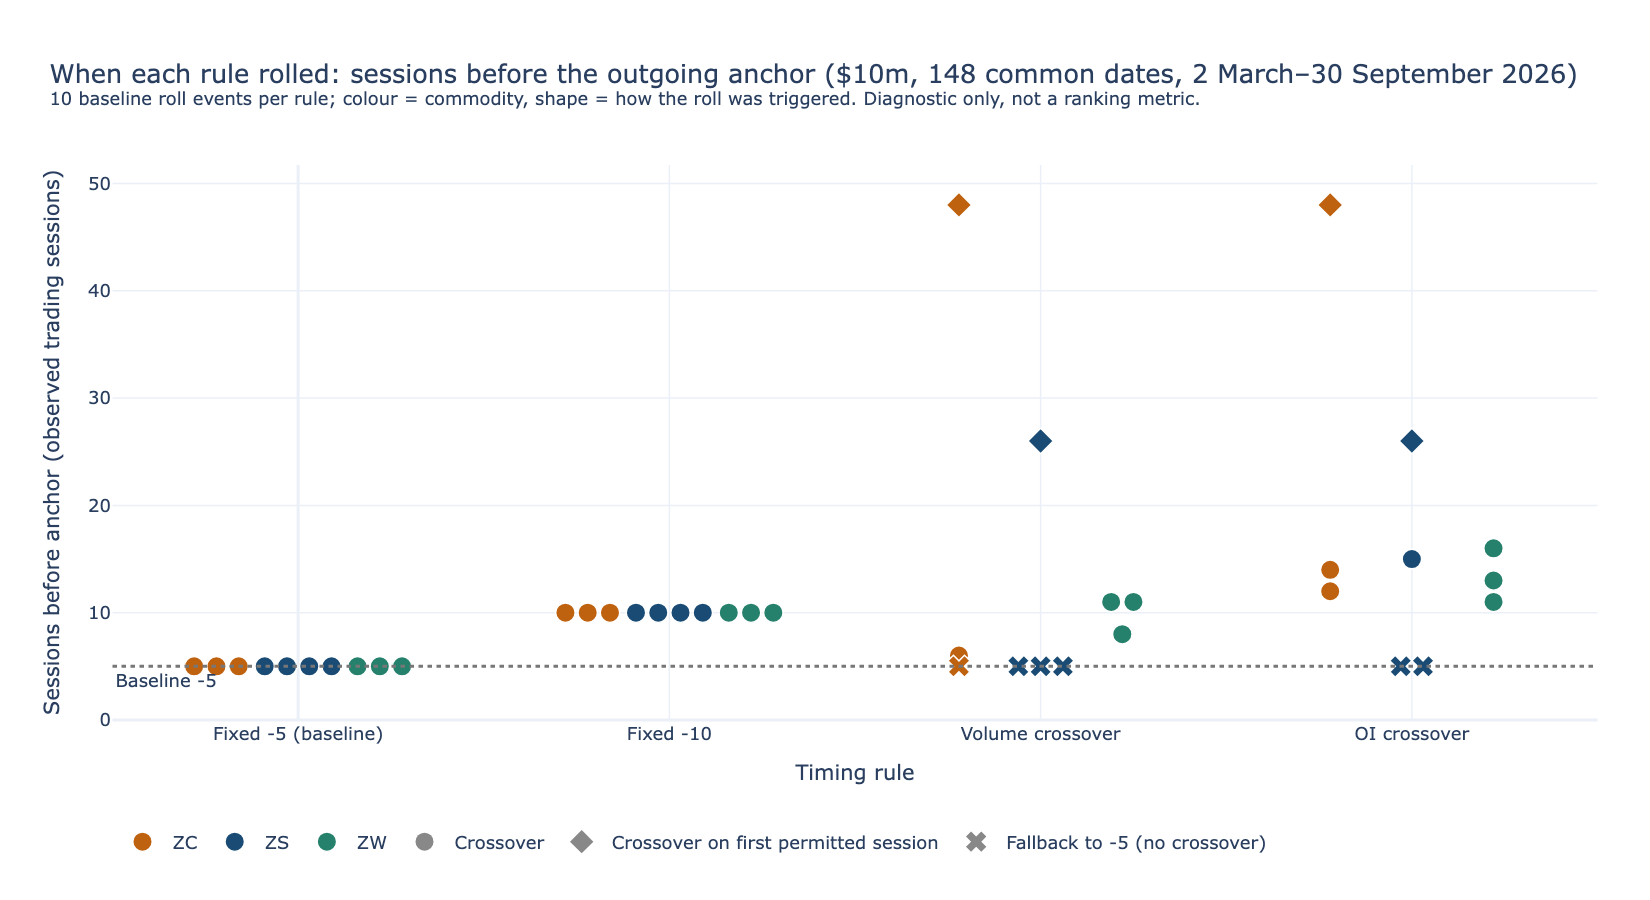

rule                                           fixed_-5  fixed_-10  \
commodity outgoing_contract incoming_contract                        
ZC        ZCK6              ZCN6                    5.0       10.0   
          ZCN6              ZCU6                    5.0       10.0   
          ZCU6              ZCZ6                    5.0       10.0   
ZS        ZSK6              ZSN6                    5.0       10.0   
          ZSN6              ZSQ6                    5.0       10.0   
          ZSQ6              ZSU6                    5.0       10.0   
          ZSU6              ZSX6                    5.0       10.0   
ZW        ZWK6              ZWN6                    5.0       10.0   
          ZWN6              ZWU6                    5.0       10.0   
          ZWU6              ZWZ6                    5.0       10.0   

rule                                           volume_crossover  oi_crossover  
commodity outgoing_contract incoming_contract                                  
ZC        ZCK6              ZCN6                            6.0          14.0  
          ZCN6              ZCU6                            5.0          12.0  
          ZCU6              ZCZ6                           48.0          48.0  
ZS        ZSK6              ZSN6                            5.0          15.0  
          ZSN6              ZSQ6                            5.0           5.0  
          ZSQ6              ZSU6                            5.0           5.0  
          ZSU6              ZSX6                           26.0          26.0  
ZW        ZWK6              ZWN6                           11.0          13.0  
          ZWN6              ZWU6                            8.0          11.0  
          ZWU6              ZWZ6                           11.0          16.0

In [5]:
png = out / "roll_trigger_distribution.png"
display(Image(png)) if png.exists() else trigger_figure(result).show()
events = pd.DataFrame(event_rows(result))
events.pivot_table(index=["commodity", "outgoing_contract", "incoming_contract"], columns="rule",
                   values="sessions_before_anchor")[list(LABELS)]

In [6]:
sel, rows = result["selection"], sorted(summary_rows(result), key=lambda r: r["tracking_rmse_bps_daily"])
margin = rows[1]["tracking_rmse_bps_daily"] - rows[0]["tracking_rmse_bps_daily"]
display(Markdown(
    f"**Selected timing rule at $10m: {LABELS[sel['preferred_rule']]}** "
    f"({rows[0]['tracking_rmse_bps_daily']:.6f} daily bp vs {rows[1]['tracking_rmse_bps_daily']:.6f} for "
    f"{LABELS[rows[1]['rule']]}; margin {margin:.6f} bp). Tie rule triggered: **{len(sel['tied_rules']) > 1}**. "
    "Limitation: timing is tested with destination fixed at next deferred, and two crossover rolls bypass "
    "the thin September contract, overlapping with destination behaviour."))

**Selected timing rule at $10m: OI crossover** (6.269433 daily bp vs 6.383168 for Fixed -10; margin 0.113735 bp). Tie rule triggered: **False**. Limitation: timing is tested with destination fixed at next deferred, and two crossover rolls bypass the thin September contract, overlapping with destination behaviour.

In [7]:
import json
manifest = write_outputs(result, out, json.loads((HANDOFF / "output_hashes.json").read_text()))
print("Chart PNGs registered:", chart_exports_verified(out))
for name in sorted(manifest["output_hashes"]):
    print("outputs/person2/" + name)

Chart PNGs registered: True
outputs/person2/HANDOFF.md
outputs/person2/chart_export.json
outputs/person2/roll_events_by_rule.csv
outputs/person2/roll_timing_daily.csv
outputs/person2/roll_timing_summary.csv
outputs/person2/roll_trigger_distribution.json
outputs/person2/roll_trigger_distribution.png
outputs/person2/tracking_rmse_by_roll_rule.json
outputs/person2/tracking_rmse_by_roll_rule.png
